# Phase 2 — Notebook 3: 9-Qubit Shor Error Correction Code

## What this notebook does:
We build the **Shor code** — the first quantum code that can correct **both** bit-flip AND phase-flip errors.

## How it works (recap):
The Shor code is the **Phase-Flip code wrapped around the Bit-Flip code**:
- **Outer layer:** Encode 1 qubit into 3 "blocks" using phase-flip protection (Hadamard + CNOT)
- **Inner layer:** Within each block, encode 1 qubit into 3 physical qubits using bit-flip protection (CNOT)
- **Result:** 1 logical qubit protected by 9 physical qubits

## Qubit layout:
```
Block A: q0, q1, q2   (bit-flip protected)
Block B: q3, q4, q5   (bit-flip protected)
Block C: q6, q7, q8   (bit-flip protected)
Blocks A, B, C together: phase-flip protected
```

---
## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity

from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    pauli_error,
    depolarizing_error,
    amplitude_damping_error,
)

plt.rcParams['figure.dpi'] = 110
np.random.seed(42)

print('Libraries loaded!')

Libraries loaded!


---
## Step 2: Build the 9-Qubit Shor Code Circuit

This is the big one. The circuit has these stages:

### ENCODING (2 layers):
1. **Phase-flip encoding:** Spread q0 across 3 blocks using H + CNOT
2. **Bit-flip encoding:** Within each block, spread across 3 qubits using CNOT

### NOISE:
3. Apply noise to all 9 data qubits

### CORRECTION (2 rounds):
4. **Bit-flip correction:** Fix bit-flips within each block (6 ancillas)
5. **Phase-flip correction:** Undo bit-flip encoding, fix phase-flips across blocks (2 ancillas)

### DECODING:
6. Undo phase-flip encoding, measure the original qubit

In [2]:
def build_shor_circuit(initial_state='0', add_noise_gate=True):
    """
    Build the full 9-qubit Shor error correction circuit.
    
    Qubits:
      data[0-8]:  9 data qubits (3 blocks of 3)
      bf_anc[0-5]: 6 ancillas for bit-flip detection (2 per block)
      pf_anc[0-1]: 2 ancillas for phase-flip detection
    """
    
    # === CREATE REGISTERS ===
    data = QuantumRegister(9, 'data')          # 9 data qubits
    bf_anc = QuantumRegister(6, 'bf_anc')      # 6 bit-flip ancillas (2 per block)
    pf_anc = QuantumRegister(2, 'pf_anc')      # 2 phase-flip ancillas
    
    bf_syn = ClassicalRegister(6, 'bf_syn')    # 6 classical bits for bit-flip syndromes
    pf_syn = ClassicalRegister(2, 'pf_syn')    # 2 classical bits for phase-flip syndrome
    output = ClassicalRegister(1, 'output')    # 1 bit for final measurement
    
    circuit = QuantumCircuit(data, bf_anc, pf_anc, bf_syn, pf_syn, output)
    
    # ==========================================
    # STAGE 1: PREPARE THE INITIAL STATE
    # ==========================================
    if initial_state == '1':
        circuit.x(data[0])
    elif initial_state == '+':
        circuit.h(data[0])
    
    circuit.barrier(label='Prepared')
    
    # ==========================================
    # STAGE 2: PHASE-FLIP ENCODING (outer layer)
    # ==========================================
    # Spread q0 across 3 blocks: q0→Block A, q3→Block B, q6→Block C
    circuit.cx(data[0], data[3])   # CNOT: q0 → q3
    circuit.cx(data[0], data[6])   # CNOT: q0 → q6
    
    # Apply Hadamard to the "leader" of each block
    # This converts the encoding to protect against phase-flips
    circuit.h(data[0])   # Block A leader
    circuit.h(data[3])   # Block B leader
    circuit.h(data[6])   # Block C leader
    
    circuit.barrier(label='Phase Encoded')
    
    # ==========================================
    # STAGE 3: BIT-FLIP ENCODING (inner layer)
    # ==========================================
    # Within each block, spread across 3 qubits
    
    # Block A: q0 → q1, q0 → q2
    circuit.cx(data[0], data[1])
    circuit.cx(data[0], data[2])
    
    # Block B: q3 → q4, q3 → q5
    circuit.cx(data[3], data[4])
    circuit.cx(data[3], data[5])
    
    # Block C: q6 → q7, q6 → q8
    circuit.cx(data[6], data[7])
    circuit.cx(data[6], data[8])
    
    circuit.barrier(label='Fully Encoded')
    
    # ==========================================
    # STAGE 4: NOISE (hits all 9 data qubits)
    # ==========================================
    if add_noise_gate:
        for i in range(9):
            circuit.id(data[i])   # Idle gate — noise attaches here
    
    circuit.barrier(label='Noise')
    
    # ==========================================
    # STAGE 5: BIT-FLIP CORRECTION (per block)
    # ==========================================
    # Same syndrome logic as Notebook 1, repeated for each block
    
    # --- Block A (q0, q1, q2) using bf_anc[0], bf_anc[1] ---
    circuit.cx(data[0], bf_anc[0])
    circuit.cx(data[1], bf_anc[0])   # bf_anc[0] = "are q0 and q1 same?"
    circuit.cx(data[1], bf_anc[1])
    circuit.cx(data[2], bf_anc[1])   # bf_anc[1] = "are q1 and q2 same?"
    
    circuit.measure(bf_anc[0], bf_syn[0])
    circuit.measure(bf_anc[1], bf_syn[1])
    
    # --- Block B (q3, q4, q5) using bf_anc[2], bf_anc[3] ---
    circuit.cx(data[3], bf_anc[2])
    circuit.cx(data[4], bf_anc[2])
    circuit.cx(data[4], bf_anc[3])
    circuit.cx(data[5], bf_anc[3])
    
    circuit.measure(bf_anc[2], bf_syn[2])
    circuit.measure(bf_anc[3], bf_syn[3])
    
    # --- Block C (q6, q7, q8) using bf_anc[4], bf_anc[5] ---
    circuit.cx(data[6], bf_anc[4])
    circuit.cx(data[7], bf_anc[4])
    circuit.cx(data[7], bf_anc[5])
    circuit.cx(data[8], bf_anc[5])
    
    circuit.measure(bf_anc[4], bf_syn[4])
    circuit.measure(bf_anc[5], bf_syn[5])
    
    circuit.barrier(label='BF Syndrome')
    
    # Apply corrections based on syndrome (same logic as Notebook 1).
    # Qiskit 2.x removed InstructionSet.c_if() — use if_test instead.
    # Block A corrections
    with circuit.if_test((bf_syn, 1)):
        circuit.x(data[0])    # syndrome 000001 → q0 flipped
    with circuit.if_test((bf_syn, 3)):
        circuit.x(data[1])    # syndrome 000011 → q1 flipped
    with circuit.if_test((bf_syn, 2)):
        circuit.x(data[2])    # syndrome 000010 → q2 flipped
    
    # Block B corrections
    with circuit.if_test((bf_syn, 4)):
        circuit.x(data[3])    # syndrome 000100 → q3 flipped
    with circuit.if_test((bf_syn, 12)):
        circuit.x(data[4])    # syndrome 001100 → q4 flipped
    with circuit.if_test((bf_syn, 8)):
        circuit.x(data[5])    # syndrome 001000 → q5 flipped
    
    # Block C corrections
    with circuit.if_test((bf_syn, 16)):
        circuit.x(data[6])    # syndrome 010000 → q6 flipped
    with circuit.if_test((bf_syn, 48)):
        circuit.x(data[7])    # syndrome 110000 → q7 flipped
    with circuit.if_test((bf_syn, 32)):
        circuit.x(data[8])    # syndrome 100000 → q8 flipped
    
    circuit.barrier(label='BF Corrected')
    
    # ==========================================
    # STAGE 6: UNDO BIT-FLIP ENCODING
    # ==========================================
    # Reverse inner encoding to get back to 3 block leaders
    circuit.cx(data[0], data[2])
    circuit.cx(data[0], data[1])
    
    circuit.cx(data[3], data[5])
    circuit.cx(data[3], data[4])
    
    circuit.cx(data[6], data[8])
    circuit.cx(data[6], data[7])
    
    circuit.barrier(label='BF Decoded')
    
    # ==========================================
    # STAGE 7: PHASE-FLIP CORRECTION
    # ==========================================
    # Apply H to convert phase-flips into bit-flips
    circuit.h(data[0])
    circuit.h(data[3])
    circuit.h(data[6])
    
    # Syndrome measurement across blocks
    circuit.cx(data[0], pf_anc[0])
    circuit.cx(data[3], pf_anc[0])   # pf_anc[0] = "are Block A and B same?"
    
    circuit.cx(data[3], pf_anc[1])
    circuit.cx(data[6], pf_anc[1])   # pf_anc[1] = "are Block B and C same?"
    
    circuit.measure(pf_anc[0], pf_syn[0])
    circuit.measure(pf_anc[1], pf_syn[1])
    
    circuit.barrier(label='PF Syndrome')
    
    # Phase-flip corrections
    with circuit.if_test((pf_syn, 1)):
        circuit.x(data[0])   # syndrome 01 → Block A had phase error
    with circuit.if_test((pf_syn, 3)):
        circuit.x(data[3])   # syndrome 11 → Block B had phase error
    with circuit.if_test((pf_syn, 2)):
        circuit.x(data[6])   # syndrome 10 → Block C had phase error
    
    circuit.barrier(label='PF Corrected')
    
    # ==========================================
    # STAGE 8: UNDO PHASE-FLIP ENCODING
    # ==========================================
    circuit.cx(data[0], data[6])
    circuit.cx(data[0], data[3])
    
    # Measure the original data qubit
    circuit.measure(data[0], output[0])
    
    return circuit


# Build and display
example = build_shor_circuit('0')
print(f'Total qubits: {example.num_qubits}')
print(f'  Data qubits:           9')
print(f'  Bit-flip ancillas:     6 (2 per block)')
print(f'  Phase-flip ancillas:   2')
print(f'  Total:                17 qubits')
print()
print('Circuit is too large to draw nicely, but it works!')

Total qubits: 17
  Data qubits:           9
  Bit-flip ancillas:     6 (2 per block)
  Phase-flip ancillas:   2
  Total:                17 qubits

Circuit is too large to draw nicely, but it works!


---
## Step 3: Noise Models

In [3]:
def make_bit_flip_noise(p):
    error = pauli_error([('X', p), ('I', 1 - p)])
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ['id'])
    return nm

def make_depolarizing_noise(p):
    error = depolarizing_error(p, 1)
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ['id'])
    return nm

def make_amplitude_damping_noise(gamma):
    error = amplitude_damping_error(gamma)
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(error, ['id'])
    return nm

noise_makers = {
    'Bit-Flip':          make_bit_flip_noise,
    'Depolarizing':      make_depolarizing_noise,
    'Amplitude Damping': make_amplitude_damping_noise,
}

print('Noise models ready!')

Noise models ready!


---
## Step 4: Sanity Check

In [4]:
noise_prob = 0.05  # 5% noise (lower than other notebooks — Shor code uses more qubits)
shots = 5000

# WITH Shor code correction
corrected_circuit = build_shor_circuit('0')
noisy_sim = AerSimulator(noise_model=make_depolarizing_noise(noise_prob))
corrected_counts = noisy_sim.run(corrected_circuit, shots=shots).result().get_counts()

# output is the first register in the bitstring (created last, so it's listed leftmost)
corrected_errors = sum(count for bitstring, count in corrected_counts.items()
                       if bitstring.split()[0] == '1')
corrected_error_rate = corrected_errors / shots

# WITHOUT correction
bare_circuit = QuantumCircuit(1, 1)
bare_circuit.id(0)
bare_circuit.measure(0, 0)

bare_sim = AerSimulator(noise_model=make_depolarizing_noise(noise_prob))
bare_counts = bare_sim.run(bare_circuit, shots=shots).result().get_counts()
bare_errors = bare_counts.get('1', 0)
bare_error_rate = bare_errors / shots

print(f'Physical error rate (no correction):  {bare_error_rate:.4f}')
print(f'Logical error rate (Shor code):       {corrected_error_rate:.4f}')
print()
if corrected_error_rate < bare_error_rate:
    improvement = (1 - corrected_error_rate / bare_error_rate) * 100
    print(f'Shor code HELPED! Error reduced by {improvement:.1f}%')
else:
    print('Shor code did NOT help at this noise level')
print()
print('Note: Shor code uses 9 qubits, so it has more places for noise to hit.')
print('It needs LOWER noise to outperform the bare qubit.')

Physical error rate (no correction):  0.0260
Logical error rate (Shor code):       0.0126

Shor code HELPED! Error reduced by 51.5%

Note: Shor code uses 9 qubits, so it has more places for noise to hit.
It needs LOWER noise to outperform the bare qubit.


---
## Step 5: Full Experiment — Logical vs Physical Error Rate

In [5]:
noise_levels = [0.001, 0.005, 0.01, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.18, 0.20]
shots = 10000
test_states = ['0', '1']


def get_logical_error_rate(initial_state, noise_type, noise_prob, num_shots):
    circuit = build_shor_circuit(initial_state)
    noise_model = noise_makers[noise_type](noise_prob)
    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    wrong_output = '1' if initial_state == '0' else '0'
    errors = sum(count for bitstring, count in counts.items()
                 if bitstring.split()[0] == wrong_output)
    return errors / num_shots


def get_physical_error_rate(initial_state, noise_type, noise_prob, num_shots):
    circuit = QuantumCircuit(1, 1)
    if initial_state == '1':
        circuit.x(0)
    circuit.id(0)
    circuit.measure(0, 0)
    
    noise_model = noise_makers[noise_type](noise_prob)
    sim = AerSimulator(noise_model=noise_model)
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    wrong_output = '1' if initial_state == '0' else '0'
    return counts.get(wrong_output, 0) / num_shots


# === RUN ALL EXPERIMENTS ===
all_results = []

for noise_type in noise_makers:
    for state in test_states:
        for p in noise_levels:
            logical_err = get_logical_error_rate(state, noise_type, p, shots)
            physical_err = get_physical_error_rate(state, noise_type, p, shots)
            
            all_results.append({
                'noise_type': noise_type,
                'initial_state': f'|{state}⟩',
                'noise_prob': p,
                'physical_error_rate': round(physical_err, 5),
                'logical_error_rate': round(logical_err, 5),
                'code_helps': logical_err < physical_err,
            })
            
print(f'Done! Ran {len(all_results)} experiments.')
results_df = pd.DataFrame(all_results)
results_df.head(10)

Done! Ran 66 experiments.


,noise_type,initial_state,noise_prob,physical_error_rate,logical_error_rate,code_helps
0,Bit-Flip,|0⟩,0.001,0.0005,0.0,True
1,Bit-Flip,|0⟩,0.005,0.0055,0.0,True
2,Bit-Flip,|0⟩,0.010,0.0088,0.0,True
3,Bit-Flip,|0⟩,0.020,0.0184,0.0,True
4,Bit-Flip,|0⟩,0.050,0.0501,0.0,True
5,Bit-Flip,|0⟩,0.080,0.0843,0.0,True
6,Bit-Flip,|0⟩,0.100,0.1039,0.0,True
7,Bit-Flip,|0⟩,0.120,0.1221,0.0,True
8,Bit-Flip,|0⟩,0.150,0.1553,0.0,True
9,Bit-Flip,|0⟩,0.180,0.1791,0.0,True


---
## Step 6: Plot Physical vs Logical Error Rate

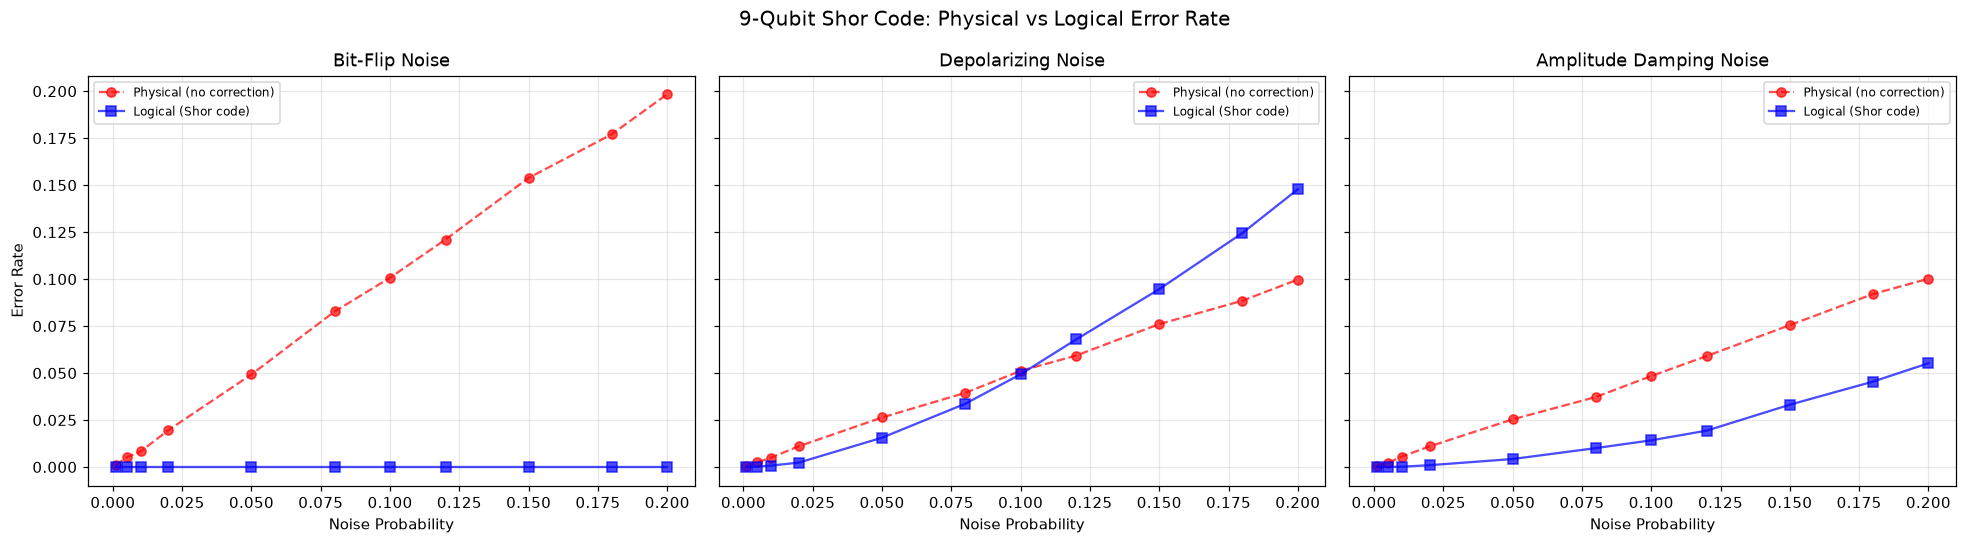

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    subset = results_df[results_df.noise_type == noise_type]
    avg = subset.groupby('noise_prob').agg({
        'physical_error_rate': 'mean',
        'logical_error_rate': 'mean'
    }).reset_index()
    
    ax.plot(avg.noise_prob, avg.physical_error_rate, 
            'r--o', label='Physical (no correction)', alpha=0.7)
    ax.plot(avg.noise_prob, avg.logical_error_rate, 
            'b-s', label='Logical (Shor code)', alpha=0.7)
    
    ax.set_title(f'{noise_type} Noise')
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel('Error Rate')
fig.suptitle('9-Qubit Shor Code: Physical vs Logical Error Rate', fontsize=13)
fig.tight_layout()

import os
os.makedirs('outputs/Phase2_Shor_Code', exist_ok=True)
fig.savefig('outputs/Phase2_Shor_Code/shor_physical_vs_logical.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 7: Find the Pseudo-Threshold

In [7]:
print('Pseudo-Threshold Estimates (9-Qubit Shor Code)')
print('=' * 55)

for noise_type in noise_makers:
    subset = results_df[results_df.noise_type == noise_type]
    avg = subset.groupby('noise_prob').agg({
        'physical_error_rate': 'mean',
        'logical_error_rate': 'mean'
    }).reset_index()
    
    threshold_found = False
    for i in range(1, len(avg)):
        phys_prev = avg.iloc[i-1]['physical_error_rate']
        phys_curr = avg.iloc[i]['physical_error_rate']
        log_prev = avg.iloc[i-1]['logical_error_rate']
        log_curr = avg.iloc[i]['logical_error_rate']
        
        if log_prev <= phys_prev and log_curr >= phys_curr:
            p_low = avg.iloc[i-1]['noise_prob']
            p_high = avg.iloc[i]['noise_prob']
            diff_prev = phys_prev - log_prev
            diff_curr = log_curr - phys_curr
            threshold = p_low + (p_high - p_low) * diff_prev / (diff_prev + diff_curr)
            print(f'{noise_type:20s} → Pseudo-threshold ≈ {threshold:.4f} ({threshold*100:.2f}%)')
            threshold_found = True
            break
    
    if not threshold_found:
        always_helps = all(avg.logical_error_rate <= avg.physical_error_rate)
        if always_helps:
            print(f'{noise_type:20s} → Code always helps in tested range')
        else:
            print(f'{noise_type:20s} → Code never helps in tested range')

Pseudo-Threshold Estimates (9-Qubit Shor Code)
Bit-Flip             → Code always helps in tested range
Depolarizing         → Pseudo-threshold ≈ 0.1035 (10.35%)
Amplitude Damping    → Code always helps in tested range


---
## Step 8: Fidelity Analysis

In [ ]:
fidelity_results = []

for noise_type in noise_makers:
    for state in ['0', '1']:
        for p in noise_levels:
            circuit = build_shor_circuit(state)
            noise_model = noise_makers[noise_type](p)
            sim = AerSimulator(noise_model=noise_model)
            counts = sim.run(circuit, shots=10000).result().get_counts()
            
            correct_output = '0' if state == '0' else '1'
            correct_count = sum(count for bitstring, count in counts.items()
                                if bitstring.split()[0] == correct_output)
            fidelity = correct_count / 10000
            
            fidelity_results.append({
                'noise_type': noise_type,
                'initial_state': f'|{state}⟩',
                'noise_prob': p,
                'fidelity_corrected': round(fidelity, 4)
            })

fidelity_df = pd.DataFrame(fidelity_results)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    subset = fidelity_df[fidelity_df.noise_type == noise_type]
    for state_name, group in subset.groupby('initial_state'):
        ax.plot(group.noise_prob, group.fidelity_corrected, marker='o', label=state_name)
    ax.set_title(f'{noise_type} Noise')
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Fidelity (after correction)')
fig.suptitle('9-Qubit Shor Code: Post-Correction Fidelity', fontsize=13)
fig.tight_layout()

import os
os.makedirs('outputs/Phase2_Shor_Code', exist_ok=True)
fig.savefig('outputs/Phase2_Shor_Code/shor_fidelity_post_correction.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 9: Compare All 3 Codes Side by Side

Load results from all 3 notebooks and plot them together.
This is the FINAL comparison graph of the project.

In [ ]:
# Load results from previous notebooks
try:
    bf_results = pd.read_csv('outputs/Phase2_BitFlip_Code/bitflip_error_rates.csv')
    pf_results = pd.read_csv('outputs/Phase2_PhaseFlip_Code/phaseflip_error_rates.csv')
    shor_results = results_df.copy()
    
    # Add code labels
    bf_results['code'] = '3-Qubit Bit-Flip'
    pf_results['code'] = '3-Qubit Phase-Flip'
    shor_results['code'] = '9-Qubit Shor'
    
    # Plot comparison for depolarizing noise (most interesting — has both error types)
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for df, code_name, color, marker in [
        (bf_results, '3-Qubit Bit-Flip', 'blue', 's'),
        (pf_results, '3-Qubit Phase-Flip', 'green', '^'),
        (shor_results, '9-Qubit Shor', 'purple', 'D'),
    ]:
        depol = df[df.noise_type == 'Depolarizing'].groupby('noise_prob').agg({
            'logical_error_rate': 'mean'
        }).reset_index()
        ax.plot(depol.noise_prob, depol.logical_error_rate, 
                f'-{marker}', color=color, label=f'{code_name} (logical)', markersize=7)
    
    # Physical error rate (same for all codes)
    phys = shor_results[shor_results.noise_type == 'Depolarizing'].groupby('noise_prob').agg({
        'physical_error_rate': 'mean'
    }).reset_index()
    ax.plot(phys.noise_prob, phys.physical_error_rate, 
            'r--o', label='Physical (no correction)', alpha=0.5)
    
    ax.set_xlabel('Noise Probability', fontsize=12)
    ax.set_ylabel('Error Rate', fontsize=12)
    ax.set_title('All 3 Codes Compared: Depolarizing Noise', fontsize=14)
    ax.legend(fontsize=10)
    ax.grid(alpha=0.3)
    fig.tight_layout()

    import os
    os.makedirs('outputs/Phase2_Shor_Code', exist_ok=True)
    fig.savefig('outputs/Phase2_Shor_Code/all_codes_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print('This graph shows which code performs best at each noise level.')
    print('The Shor code should handle depolarizing noise best (it corrects both error types).')
    
except FileNotFoundError:
    print('Run the Bit-Flip and Phase-Flip notebooks first to generate their CSV files!')
    print('Then re-run this cell.')

---
## Step 10: Save Results

In [ ]:
import os
os.makedirs('outputs/Phase2_Shor_Code', exist_ok=True)
results_df.to_csv('outputs/Phase2_Shor_Code/shor_error_rates.csv', index=False)
fidelity_df.to_csv('outputs/Phase2_Shor_Code/shor_fidelity_results.csv', index=False)

print('Saved: outputs/Phase2_Shor_Code/shor_error_rates.csv')
print('Saved: outputs/Phase2_Shor_Code/shor_fidelity_results.csv')
print()
print('='*50)
print('ALL PHASE 2 NOTEBOOKS COMPLETE!')
print('='*50)
print()
print('Summary of deliverables:')
print('  1. Phase1_Noise_Simulation.ipynb    — baseline (no correction)')
print('  2. Phase2_BitFlip_Code.ipynb        — 3-qubit bit-flip code')
print('  3. Phase2_PhaseFlip_Code.ipynb      — 3-qubit phase-flip code')
print('  4. Phase2_Shor_Code.ipynb           — 9-qubit Shor code')
print()
print('Key outputs:')
print('  - Physical vs Logical error rate curves')
print('  - Pseudo-threshold for each code under each noise type')
print('  - Post-correction fidelity analysis')
print('  - Comparison with base paper scaling law')
print('  - All 3 codes compared side by side')